In [1]:
from pathlib import Path
import sys

# Support kernels started in either the project root or Notebooks/Search.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "pyproject.toml").is_file() and (folder / "src" / "ufc_betting").is_dir()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from inside the SportsBetting project.")
for folder in (project_root, project_root / "src"):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

In [2]:
from Notebooks.Bets.simulate_and_plot import simulate_and_plot

from IPython.display import display
from ufc_betting.config import settings
from ufc_betting.BettingStrategy.betting_params import BettingParams
from ufc_betting.Models.Search.prediction_input import read_frozen_predictions
from ufc_betting.BettingStrategy.Backtest.backtest_plots import plot_bankroll_distributions
from ufc_betting.BettingStrategy.Backtest.backtest_plots import (
    plot_event_accuracy_distributions,
)

# Change this to your desired output folder (absolute paths are supported).
data_dir = settings.data_dir
plot_output_dir = settings.images_dir / "plot_pngs"
plot_output_dir.mkdir(parents=True, exist_ok=True)
(data_dir / "backtest_results").mkdir(parents=True, exist_ok=True)

def save_plot(fig, filename):
    path = plot_output_dir / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved plot: {path.resolve()}")
    return path

prediction_options = dict(split="val", model_type="open", initial_bankroll=500, show_conservative_edge_returns=False)


Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\val_logit_open_with_open.csv
open: decay disabled


{'z': 0.36000000000000004,
 'N': 1203,
 'N_parlay': 381,
 'mdd': 0.37000000000000005,
 'mdd_parlay': 0.23,
 'moneyline_max_american': None,
 'decay_rates': None,
 'moneyline_min_american': -550.0}

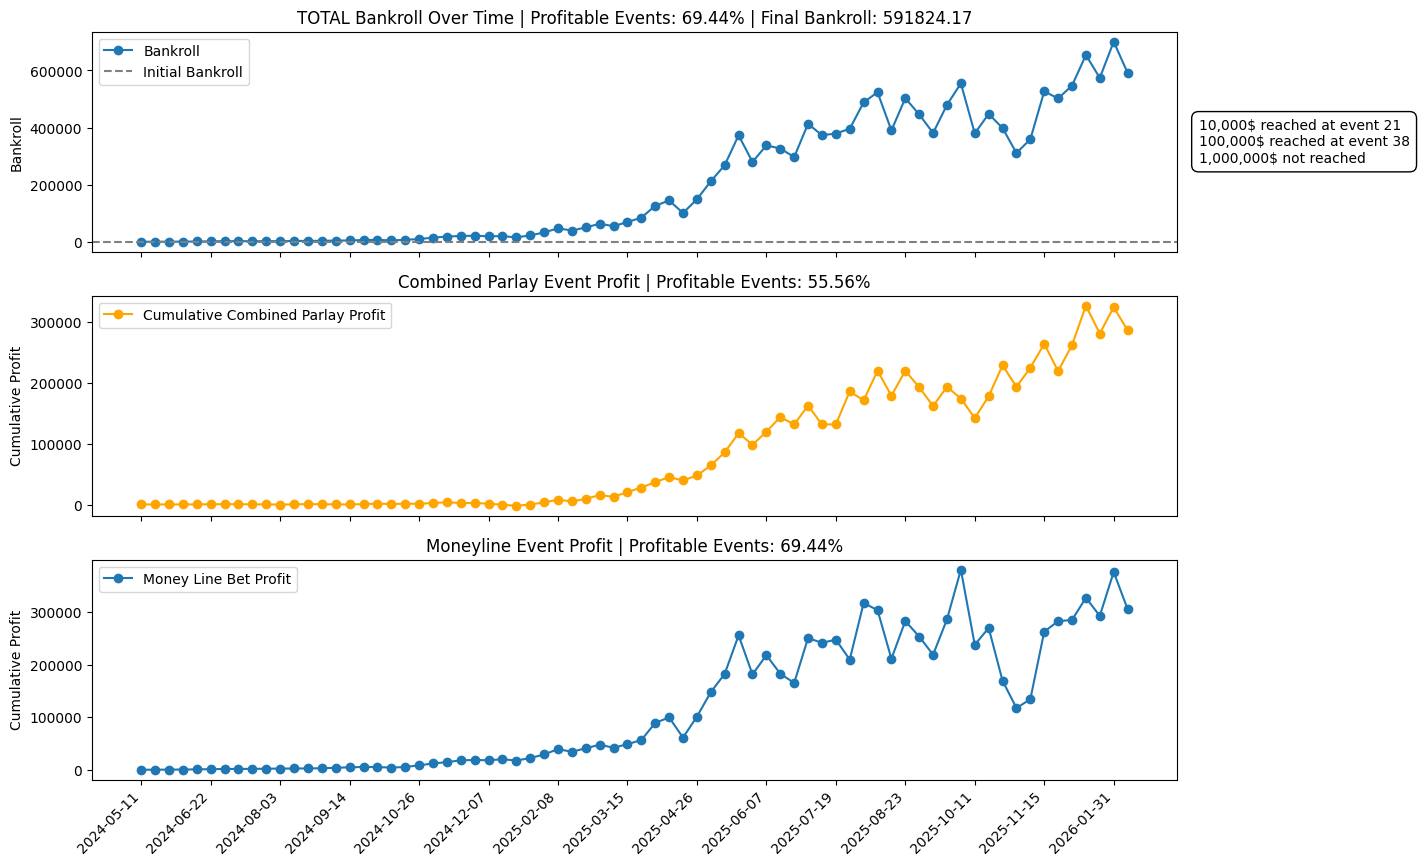

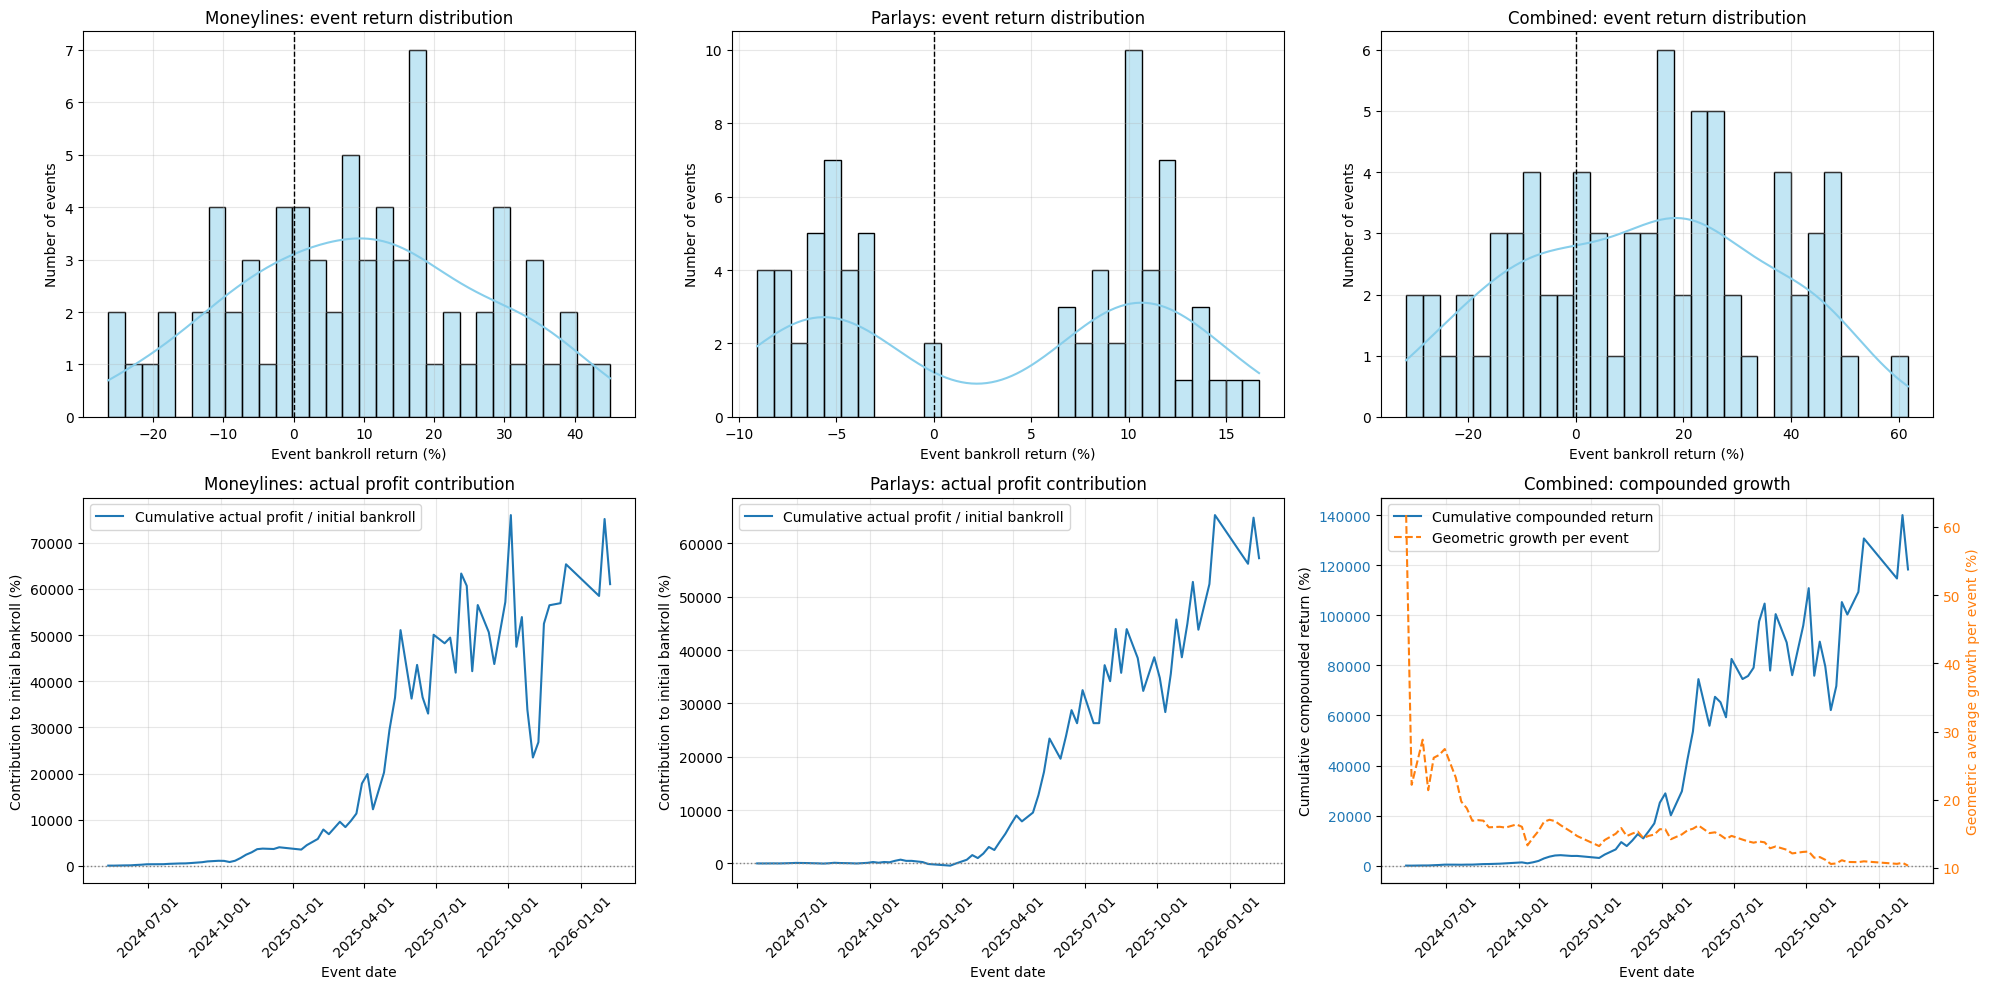

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\open_bankroll_distributions.png


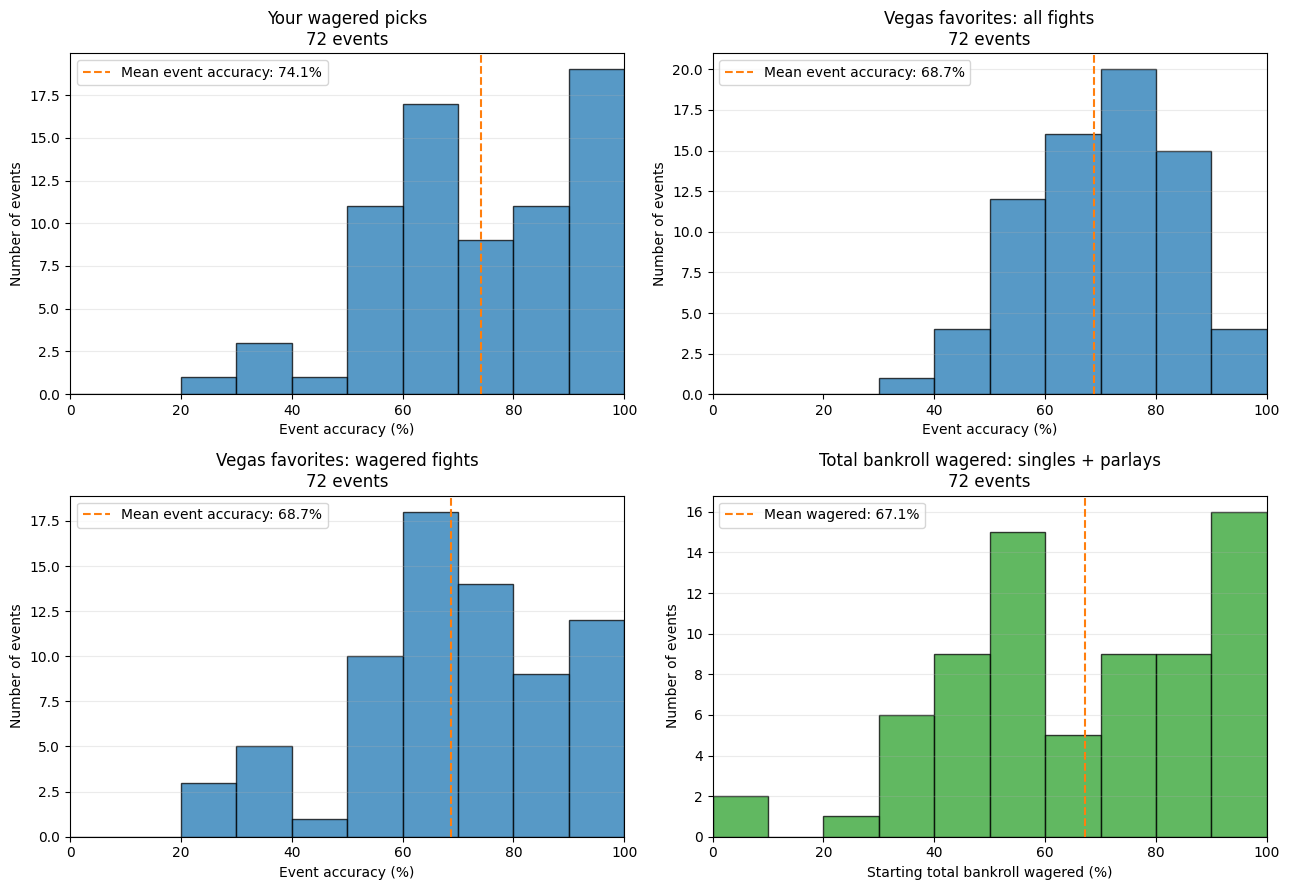

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\open_event_accuracy.png


In [3]:

moneylines, parlays = simulate_and_plot(
    odds_type="open",
    use_decay=False,
    plot_path=plot_output_dir / "open_backtest.png",
    **prediction_options,
)
distribution_fig, _ = plot_bankroll_distributions(moneylines, parlays)
save_plot(distribution_fig, "open_bankroll_distributions.png")

fig, axes, event_accuracy = plot_event_accuracy_distributions(
    moneylines, parlays, odds_type="open"
)
save_plot(fig, "open_event_accuracy.png")

moneylines.to_csv(
    data_dir / "backtest_results" / "open_moneylines.csv", index=False
)
parlays.to_csv(
    data_dir / "backtest_results" / "open_parlays.csv", index=False
)

c:\Users\jcmar\my_files\SportsBetting\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\val_logit_open_with_close1.csv
close1: decay enabled


{'z': 1.54,
 'N': 11,
 'N_parlay': 782,
 'mdd': 0.31,
 'mdd_parlay': 0.05,
 'moneyline_max_american': None,
 'decay_rates': {'k_down': 49.92299769785077,
  'k_up': 2.4770400831643937,
  'k_parlay_down': 24.91940617236104,
  'k_parlay_up': 7.134585186657787},
 'moneyline_min_american': -225.0}

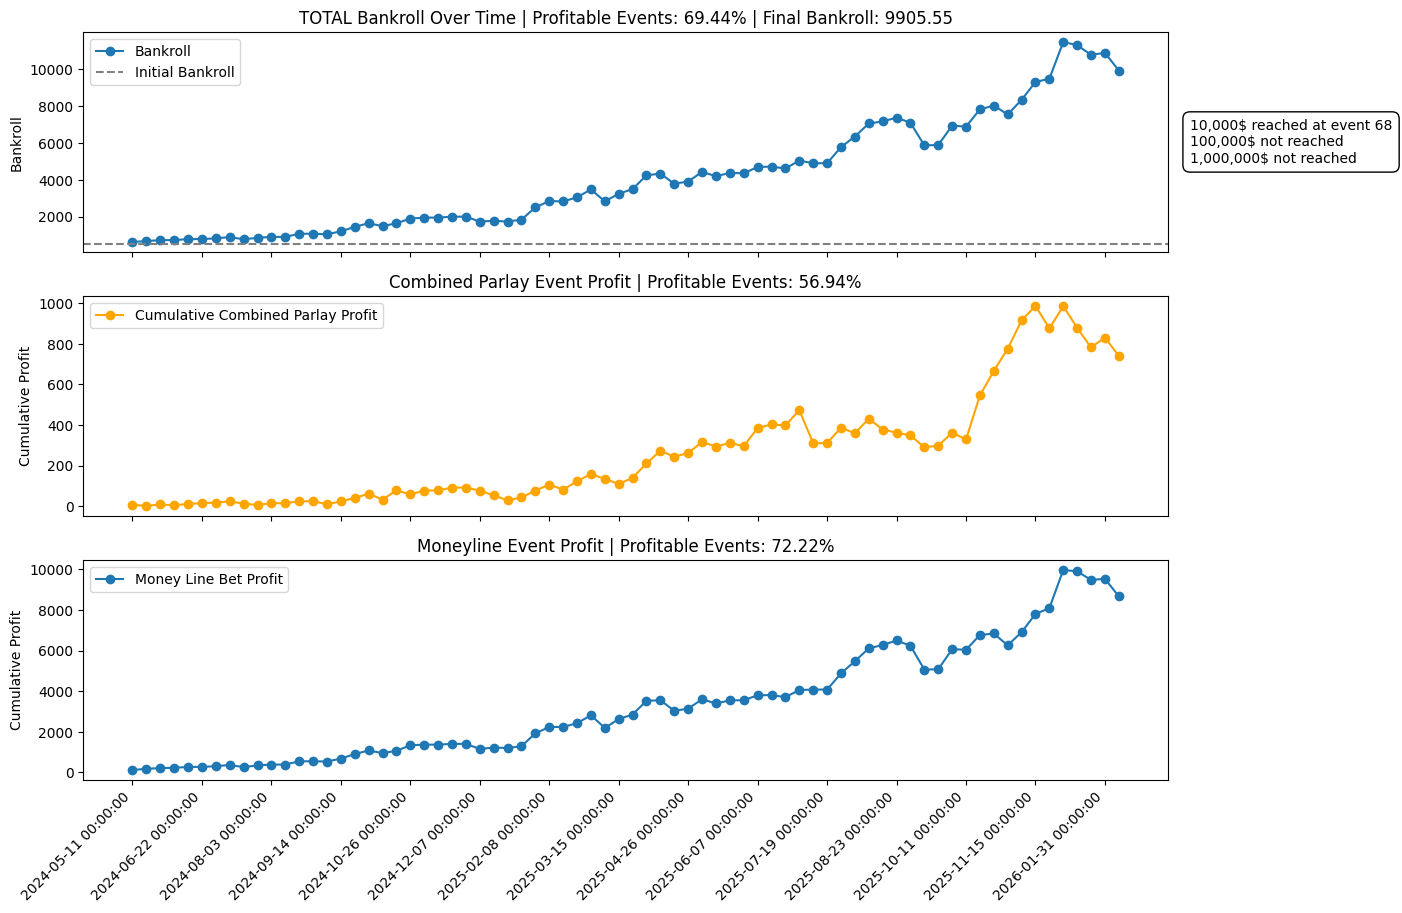

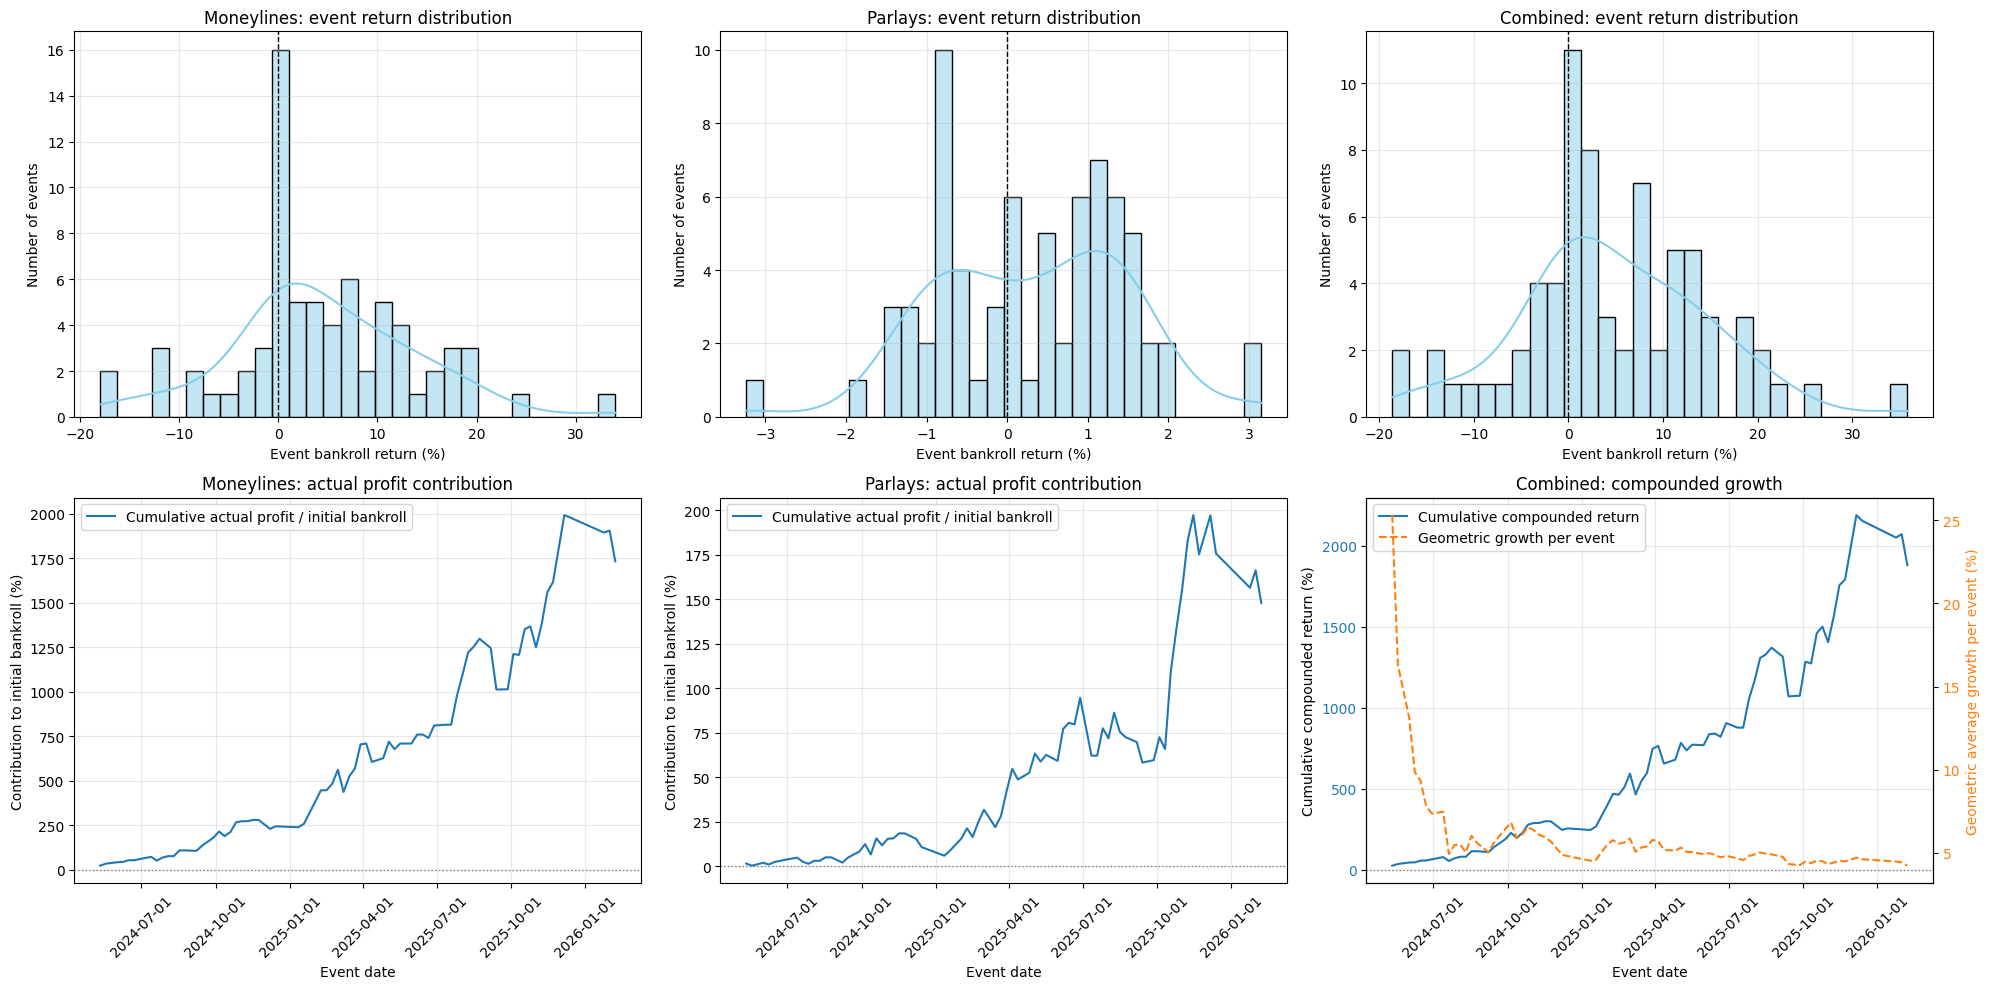

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\close1_bankroll_distributions.png


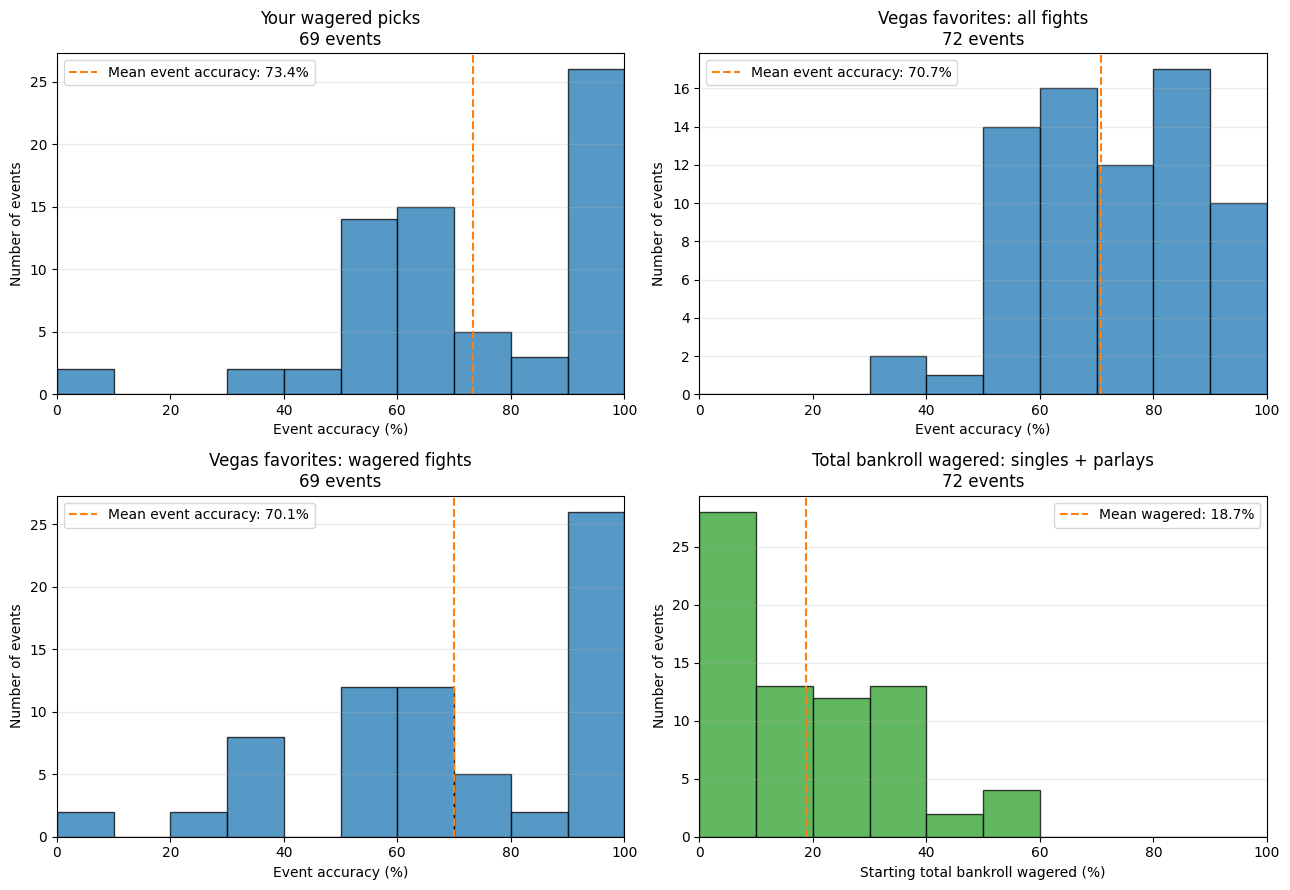

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\close1_event_accuracy.png


In [4]:
# Choose "open", "close1", or "close2".
moneylines, parlays = simulate_and_plot(
    odds_type="close1",
    plot_path=plot_output_dir / "close1.png",
    use_decay=True, 
    **prediction_options
)
distribution_fig, _ = plot_bankroll_distributions(moneylines, parlays)
save_plot(distribution_fig, "close1_bankroll_distributions.png")

fig, axes, event_accuracy = plot_event_accuracy_distributions(
    moneylines, parlays, odds_type="close1"
)
save_plot(fig, "close1_event_accuracy.png")

moneylines.to_csv(
    data_dir / "backtest_results" / "close1_moneylines.csv", index=False
)
parlays.to_csv(
    data_dir / "backtest_results" / "close1_parlays.csv", index=False
)

Predictions: C:\Users\jcmar\my_files\SportsBetting\Data\model_predictions\val_logit_open_with_close2.csv
close2: decay enabled


{'z': 1.1,
 'N': 218,
 'N_parlay': 68,
 'mdd': 0.5700000000000001,
 'mdd_parlay': 0.03,
 'moneyline_max_american': None,
 'decay_rates': {'k_down': 23.73724679964053,
  'k_up': 0.30513125637648325,
  'k_parlay_down': 0.08865501664706964,
  'k_parlay_up': 1.449275366834736},
 'moneyline_min_american': -200.0}

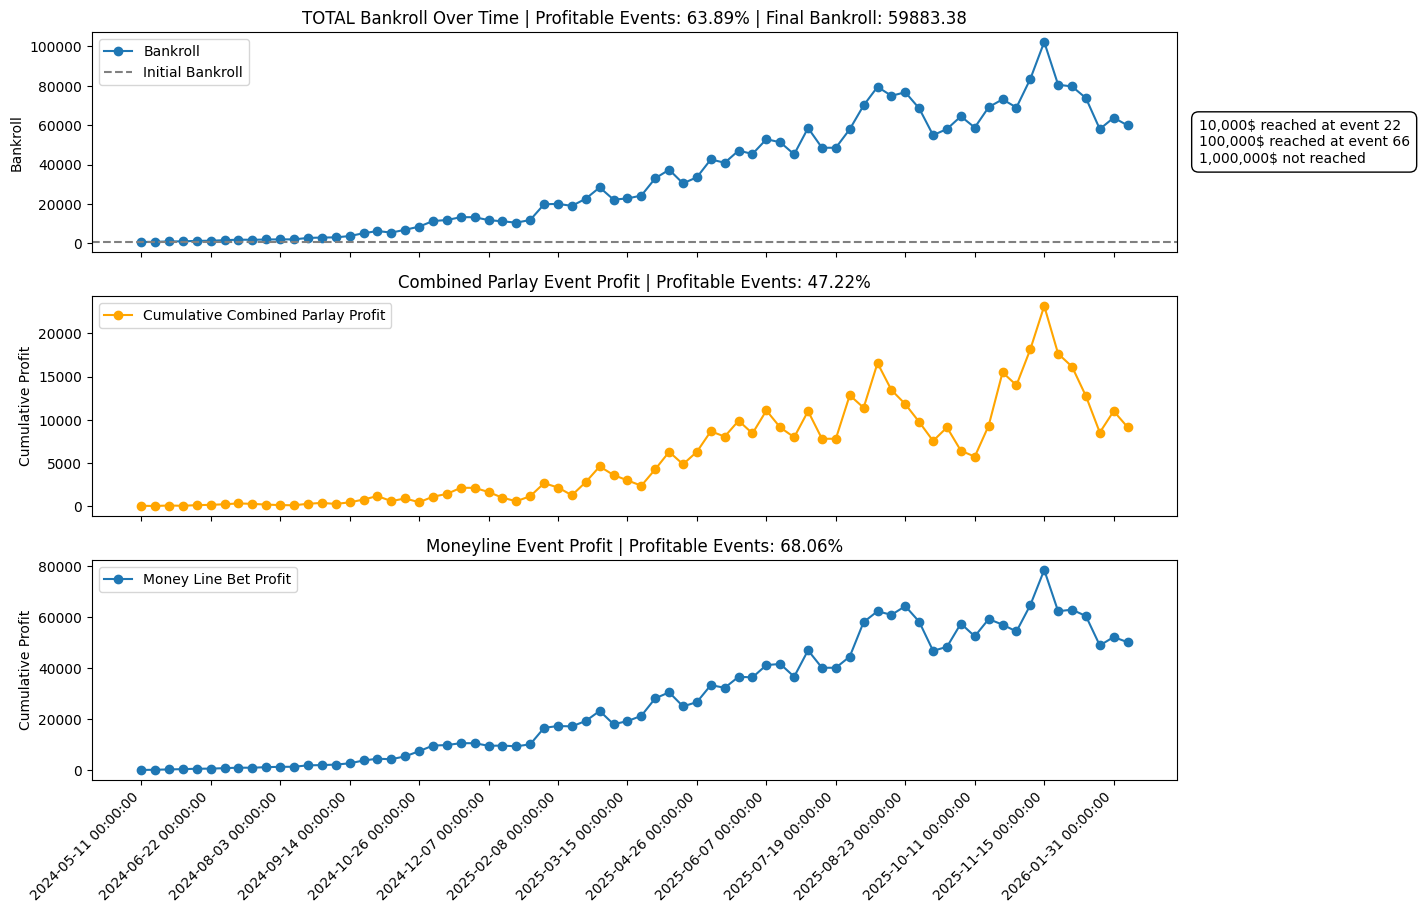

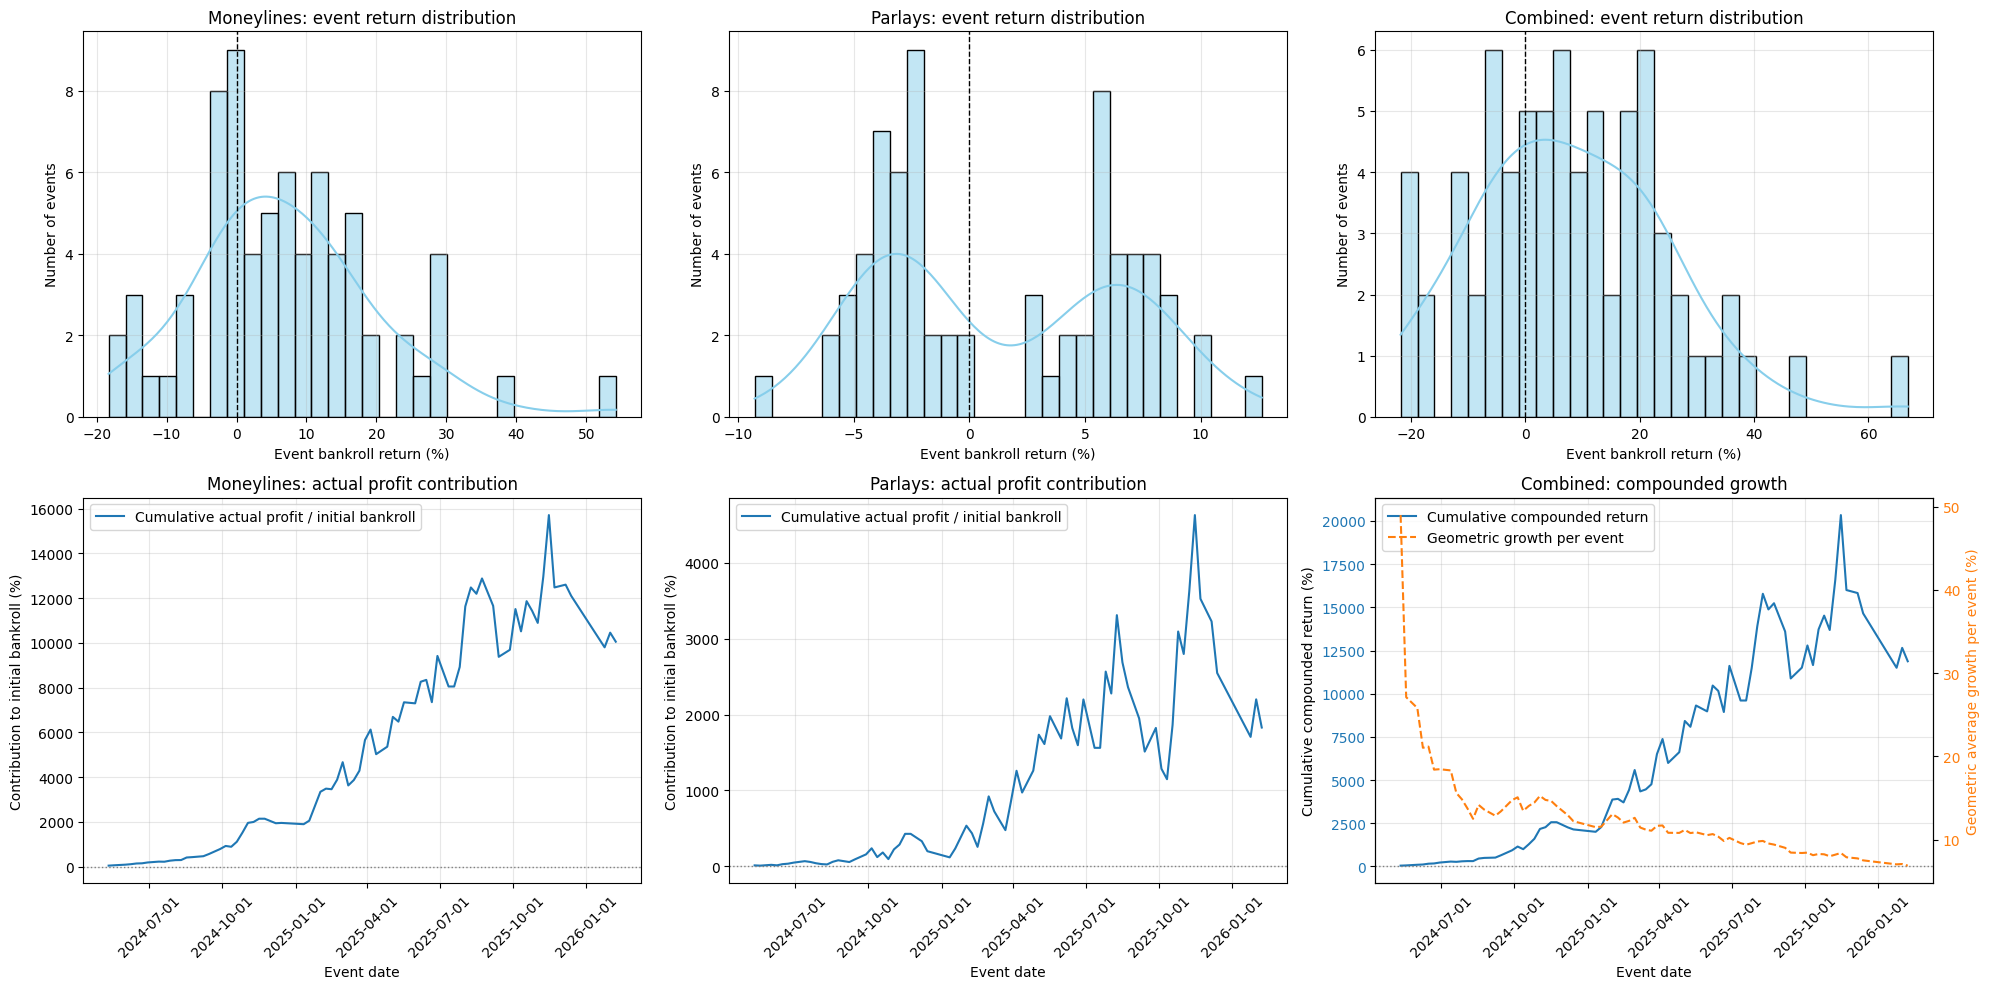

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\close2_bankroll_distributions.png


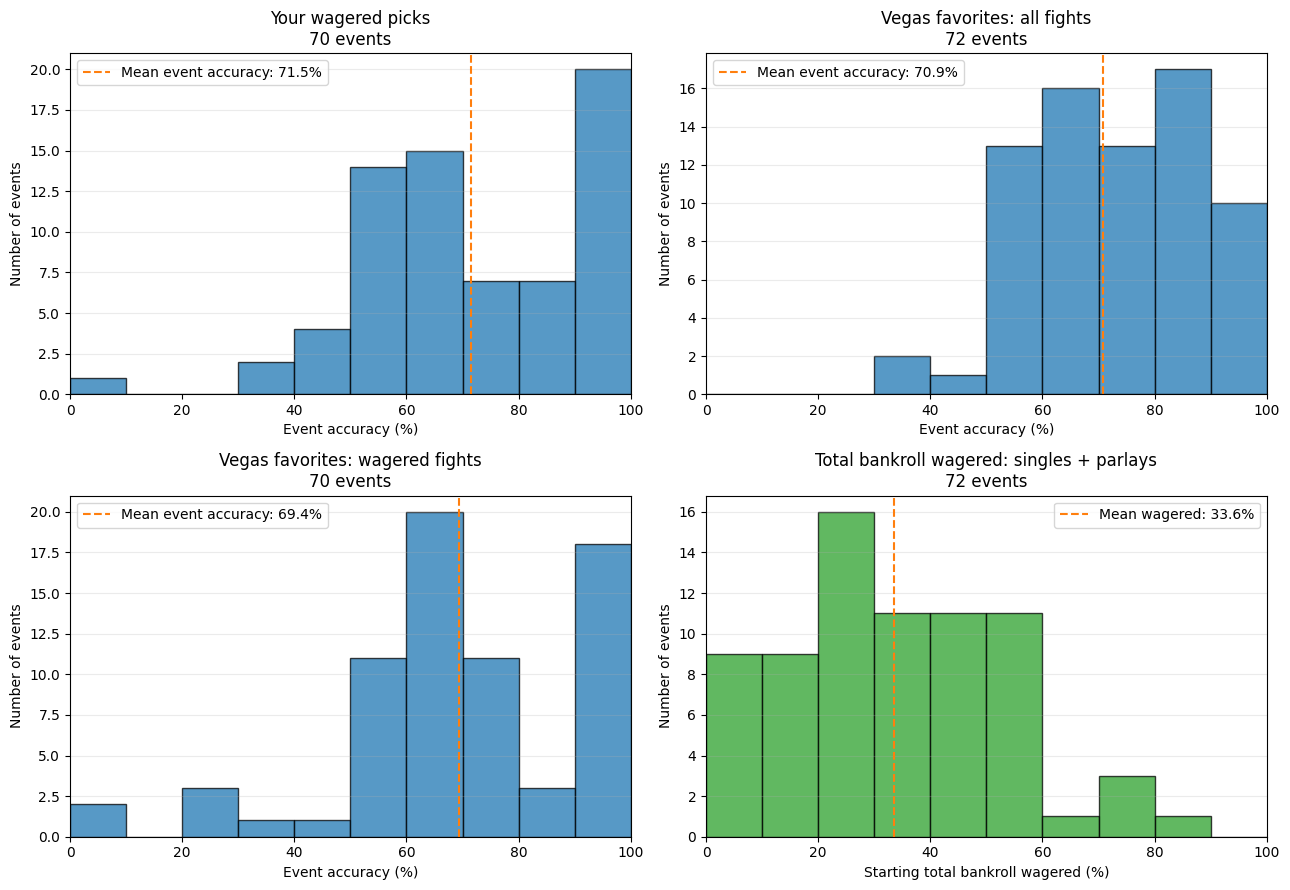

Saved plot: C:\Users\jcmar\my_files\SportsBetting\Data\images\plot_pngs\close2_event_accuracy.png


In [5]:
moneylines, parlays = simulate_and_plot(
    "close2", 
    plot_path=plot_output_dir / "close2_backtest.png", 
    use_decay=True, 
    **prediction_options
)
distribution_fig, _ = plot_bankroll_distributions(moneylines, parlays)
save_plot(distribution_fig, "close2_bankroll_distributions.png")

fig, axes, event_accuracy = plot_event_accuracy_distributions(
    moneylines, parlays, odds_type="close2"
)
save_plot(fig, "close2_event_accuracy.png")

moneylines.to_csv(
    data_dir / "backtest_results" / "close2_moneylines.csv", index=False
)
parlays.to_csv(
    data_dir / "backtest_results" / "close2_parlays.csv", index=False
)

### Bootstrap paths with and without lambda
Each market uses the same event schedules for both policies, including moneylines and parlays. Left: median cumulative return and 10th-90th percentile band. Right: the full terminal-return distribution. Symmetric-log return axes retain losses and large positive tails. These are validation-data simulations, not a new held-out evaluation.

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ufc_betting.Models.Search.exponential_decay import MoneylineDecaySearch
from ufc_betting.Models.Search.parlay_decay import ParlayDecaySearch


def plot_bootstrap_decay_comparison(n_paths=None, initial_bankroll=500, seed=42, *, parlay_only=False):
    """Compare saved close1/close2 policies using identical paths within each market.

    Reuse validation_v1 samples when present; otherwise generate n_paths (1000
    by default). No optimization or parameter writes. n_paths=None loads all
    saved samples. Ruined paths retain their exact crossing loss to the end.
    """
    data_dir = settings.data_dir
    family_label = "Parlay-only" if parlay_only else "Moneylines + parlays"
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
    simulations, summary = {}, []
    colors = {"Without lambda": "tab:blue", "With lambda": "tab:orange"}

    for row, market in enumerate(("close1", "close2")):
        params = BettingParams.load(data_dir / "kelly_params" / f"{market}.json")
        if params.decay_rates is None or params.opening_params is None:
            raise ValueError(f"{market}.json must contain saved decay_rates and opening_params")
        closing = read_frozen_predictions(
            settings.model_predictions_folder / prediction_options.get(
                "prediction_template", "{split}_logit_{model_type}_with_{odds_type}.csv"
            ).format(split=prediction_options["split"],
                     model_type=prediction_options["model_type"], odds_type=market)
        )
        # Original opening prices from these same fights; predictions stay fixed.
        opening = closing[["date", "fighter_red", "fighter_blue", "dec_open_red", "dec_open_blue"]].copy()
        folder = data_dir / "bootstrapped_events" / ("validation_v1" if prediction_options["split"] == "val" else "test_v1") / market
        mode = "load" if folder.exists() else "generate"
        metadata = json.loads((folder / "metadata.json").read_text()) if mode == "load" else None
        count = n_paths if n_paths is not None else (metadata["n_samples"] if metadata else 1000)
        engine = ParlayDecaySearch(MoneylineDecaySearch(
            closing, opening, params.opening_params, params,
            odds_type=market, k=count, initial_bankroll=initial_bankroll, seed=seed,
            bootstrap_mode=mode, bootstrap_dir=folder if mode == "load" else None,
            sample_with_replacement=metadata["replace"] if metadata else True,
        ))
        # Closing-policy stakes are the use_decay=False baseline; zero lambdas
        # would instead select opening-policy stakes at the closing prices.
        if parlay_only:
            evaluations = {
                "Without lambda": engine.evaluate_parlay_only(policy="closing"),
                "With lambda": engine.evaluate_parlay_only(
                    k_parlay_down=params.decay_rates["k_parlay_down"],
                    k_parlay_up=params.decay_rates["k_parlay_up"],
                ),
            }
        else:
            evaluations = {
                "Without lambda": engine.evaluate(policy="closing"),
                "With lambda": engine.evaluate(**params.decay_rates),
            }
        simulations[market] = {
            "path_indices": engine.path_indices.copy(),
            "bootstrap_mode": mode,
            "bet_family": family_label,
            "evaluations": evaluations,
        }
        for label, evaluated in evaluations.items():
            simulation = evaluated["simulation"]
            paths_pct = (simulation["bankroll"] / initial_bankroll - 1) * 100
            low, median, high = np.percentile(paths_pct, [10, 50, 90], axis=0)
            steps = np.arange(paths_pct.shape[1])
            color = colors[label]
            axes[row, 0].fill_between(steps, low, high, color=color, alpha=.15)
            axes[row, 0].plot(steps, median, color=color, label=label)
            terminal = simulation["terminal_returns"] * 100
            axes[row, 1].step(np.sort(terminal), np.arange(1, len(terminal)+1)/len(terminal),
                              where="post", color=color, label=label)
            summary.append({
                "market": market, "bet_family": family_label, "policy": label, "paths": len(terminal),
                "mean_return_pct": terminal.mean(), "median_return_pct": np.median(terminal),
                "std_return_pct": terminal.std(ddof=1),
                "loss_probability_pct": 100 * np.mean(terminal < 0),
                "ruin_probability_pct": 100 * np.mean(terminal <= -100),
            })
        axes[row, 0].set(title=f"{market}: median path and 10-90% band ({mode}, {count} paths)",
                         xlabel="Scheduled event", ylabel="Cumulative return (%)")
        axes[row, 0].set_yscale("symlog", linthresh=100)
        axes[row, 0].axhline(-100, color="gray", linestyle=":", linewidth=1)
        axes[row, 1].set(title=f"{market}: terminal return distribution (ECDF)",
                         xlabel="Terminal return (%)", ylabel="Fraction of paths at or below return",
                         ylim=(0, 1))
        axes[row, 1].set_xscale("symlog", linthresh=100)
        axes[row, 1].axvline(-100, color="gray", linestyle=":", linewidth=1)
        for ax in axes[row]:
            ax.legend()
            ax.grid(alpha=.2)
    fig.suptitle(f"{family_label}: bootstrap returns with and without saved lambda parameters")
    plt.show()
    summary = pd.DataFrame(summary)
    display(summary)
    paired = []
    for market, result in simulations.items():
        baseline = result["evaluations"]["Without lambda"]["simulation"]["terminal_returns"]
        fitted = result["evaluations"]["With lambda"]["simulation"]["terminal_returns"]
        delta_pp = 100 * (fitted - baseline)
        result["paired_terminal_improvement_pp"] = delta_pp
        paired.append({
            "market": market,
            "mean_improvement_pp": delta_pp.mean(),
            "median_improvement_pp": np.median(delta_pp),
            "paths_improved_pct": 100 * np.mean(delta_pp > 1e-10),
            "paths_tied_pct": 100 * np.mean(np.abs(delta_pp) <= 1e-10),
            "p10_improvement_pp": np.percentile(delta_pp, 10),
            "p90_improvement_pp": np.percentile(delta_pp, 90),
        })
    print("Paired terminal-return change: with lambda minus without lambda")
    display(pd.DataFrame(paired))
    return simulations, summary


bootstrap_comparisons, bootstrap_summary = plot_bootstrap_decay_comparison()


### Parlay-only decay comparison

The following plots compound **only parlay bets on their own bankroll**, using the same event paths for decay and no decay. Moneylines are removed before the uncertainty adjustment and exposure cap. The baseline uses closing-policy parlay stakes; decay blends opening and closing parlay stakes using the saved parlay rates, followed by closing-policy z. Zero decay rates would select opening stakes, so they are not the no-decay baseline.

Positive paired improvement means adding parlay decay helped on that path. The saved controls were fitted jointly with moneylines: this is an in-sample diagnostic of those controls, not a newly optimized parlay strategy or evidence of held-out improvement. These are historical event-bootstrap paths, not the compact synthetic fight paths.


In [ ]:
parlay_bootstrap_comparisons, parlay_bootstrap_summary = plot_bootstrap_decay_comparison(
    n_paths=1000, initial_bankroll=500, seed=42, parlay_only=True,
)
